# Lab Task 1



**Task # 01:**

Load a grayscale image and shift the entire image 10 pixels to the left. Fill the empty space on the right with black pixels. Display the original and the shifted image side by side.

In [10]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
from google.colab import files
import os

# Check if image exists
image_path = "/content/247076.png"

if not os.path.exists(image_path):
    print("Please upload your image:")
    uploaded = files.upload()
    image_path = "/content/" + list(uploaded.keys())[0]

print("Using image:", image_path)

Using image: /content/247076.png


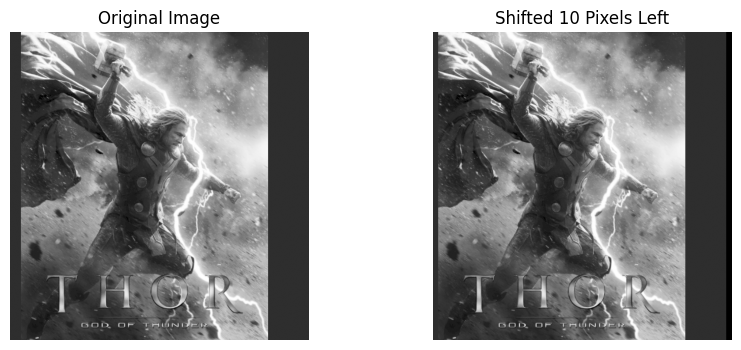

In [13]:
# Load grayscale image
img = cv2.imread("/content/247076.png", cv2.IMREAD_GRAYSCALE)

# Create transformation matrix
M = np.float32([
    [1, 0, -10],
    [0, 1, 0]
])

# Shift image 10 pixels to the left
shifted = cv2.warpAffine(
    img,
    M,
    (img.shape[1], img.shape[0]),
    borderValue=0
)

# Display images
plt.figure(figsize=(10, 4))

plt.subplot(1, 2, 1)
plt.imshow(img, cmap="gray")
plt.title("Original Image")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(shifted, cmap="gray")
plt.title("Shifted 10 Pixels Left")
plt.axis("off")

plt.show()

**Task # 02:**

Create your own 5×5 sharpening kernel (different from the one in the lab). Apply it to a slightly blurred image and compare the result with the standard 3×3 sharpening kernel. Which one looks sharper and which one introduces more noise?*italicized text*

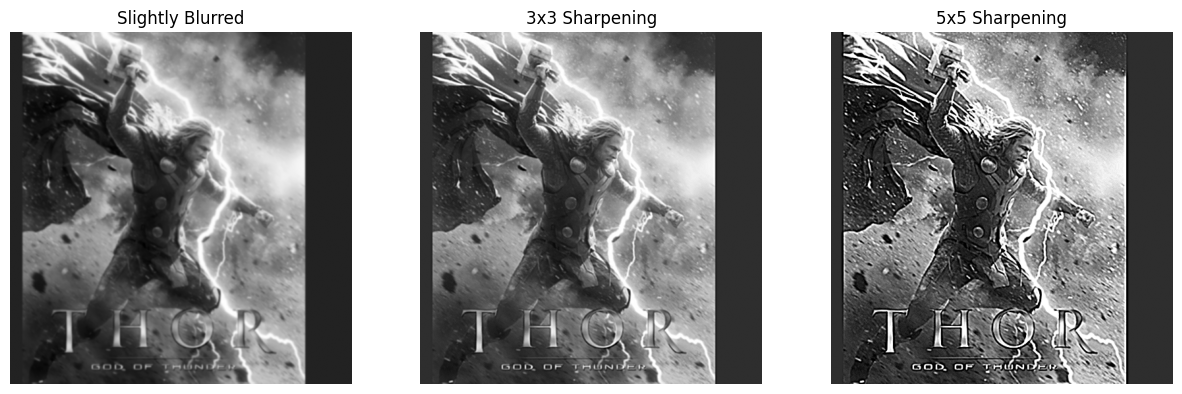

In [21]:
# Load image
img = cv2.imread("/content/247076.png")

# Convert to grayscale
gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

# Slightly blur the image
blurred = cv2.GaussianBlur(gray, (5, 5), 1)

# Standard 3x3 sharpening kernel
kernel_3x3 = np.array([
    [0, -1, 0],
    [-1, 5, -1],
    [0, -1, 0]
])

# Custom 5x5 sharpening kernel
kernel_5x5 = np.array([
    [0, 0, -1, 0, 0],
    [0, -1, -1, -1, 0],
    [-1, -1, 13, -1, -1],
    [0, -1, -1, -1, 0],
    [0, 0, -1, 0, 0]
])

# Apply sharpening
sharp_3x3 = cv2.filter2D(blurred, -1, kernel_3x3)
sharp_5x5 = cv2.filter2D(blurred, -1, kernel_5x5)

# Display
plt.figure(figsize=(15, 5))

plt.subplot(1, 3, 1)
plt.imshow(blurred, cmap="gray")
plt.title("Slightly Blurred")
plt.axis("off")

plt.subplot(1, 3, 2)
plt.imshow(sharp_3x3, cmap="gray")
plt.title("3x3 Sharpening")
plt.axis("off")

plt.subplot(1, 3, 3)
plt.imshow(sharp_5x5, cmap="gray")
plt.title("5x5 Sharpening")
plt.axis("off")

plt.show()

**Task # 03:**

Apply a strong Gaussian blur (sigma = 8) to an image, then try to recover the sharpness using the sharpening filter. Show the original, the blurred version, and the attempt to sharpen it. Comment on how well the details came back.

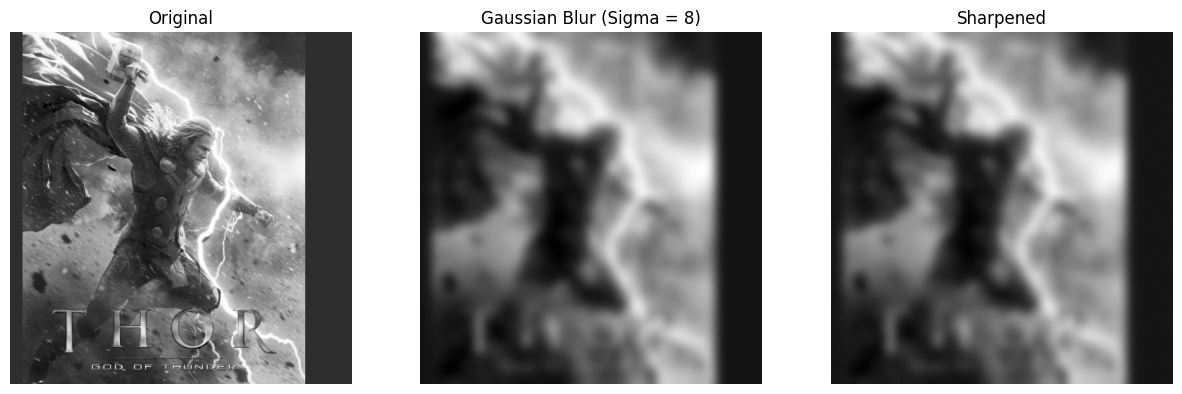

In [23]:

gray = cv2.imread("/content/247076.png", cv2.IMREAD_GRAYSCALE)


blurred = cv2.GaussianBlur(gray, (0, 0), 8)

kernel = np.array([
    [0, -1, 0],
    [-1, 5, -1],
    [0, -1, 0]
])

sharpened = cv2.filter2D(blurred, -1, kernel)

plt.figure(figsize=(15, 5))

plt.subplot(1, 3, 1)
plt.imshow(gray, cmap="gray")
plt.title("Original")
plt.axis("off")

plt.subplot(1, 3, 2)
plt.imshow(blurred, cmap="gray")
plt.title("Gaussian Blur (Sigma = 8)")
plt.axis("off")

plt.subplot(1, 3, 3)
plt.imshow(sharpened, cmap="gray")
plt.title("Sharpened")
plt.axis("off")

plt.show()

**Task # 04:**

Take a new image that has a lot of fine detail (for example a text document or a building with many windows). Convert it to grayscale and apply both a 3×3 and a 9×9 box filter. Show all three images and explain which kernel size destroys more detail.

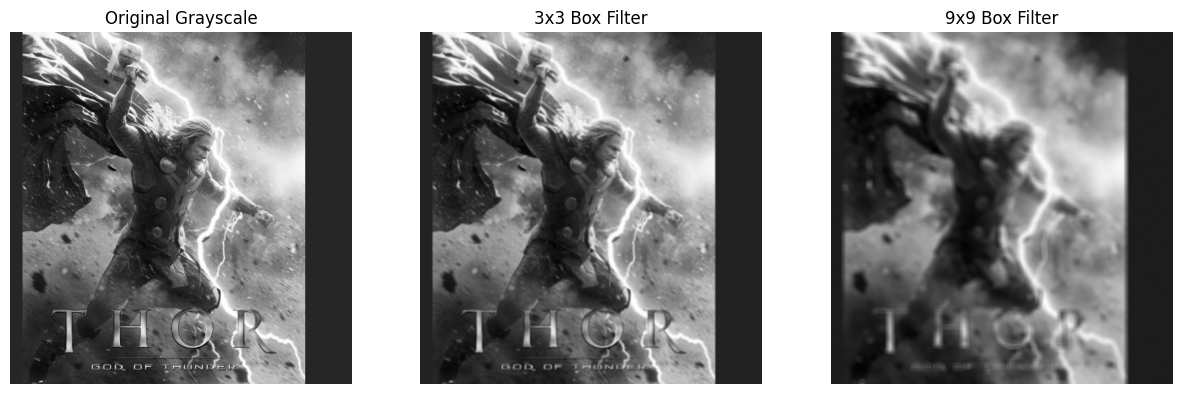

In [16]:

img = cv2.imread("/content/247076.png")

gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

box_3x3 = cv2.blur(gray, (3, 3))

box_9x9 = cv2.blur(gray, (9, 9))

plt.figure(figsize=(15, 5))
plt.subplot(1, 3, 1)
plt.imshow(gray, cmap="gray")
plt.title("Original Grayscale")
plt.axis("off")
plt.subplot(1, 3, 2)
plt.imshow(box_3x3, cmap="gray")
plt.title("3x3 Box Filter")
plt.axis("off")
plt.subplot(1, 3, 3)
plt.imshow(box_9x9, cmap="gray")
plt.title("9x9 Box Filter")
plt.axis("off")
plt.show()

**Task # 05:**

Design a sequence that first removes salt and pepper noise with a median filter, then applies a gentle Gaussian filter, then computes Sobel edges on the smoothed image and finally sharpens the smoothed result, display every stage, and write a short analysis of how well the edges were preserved.

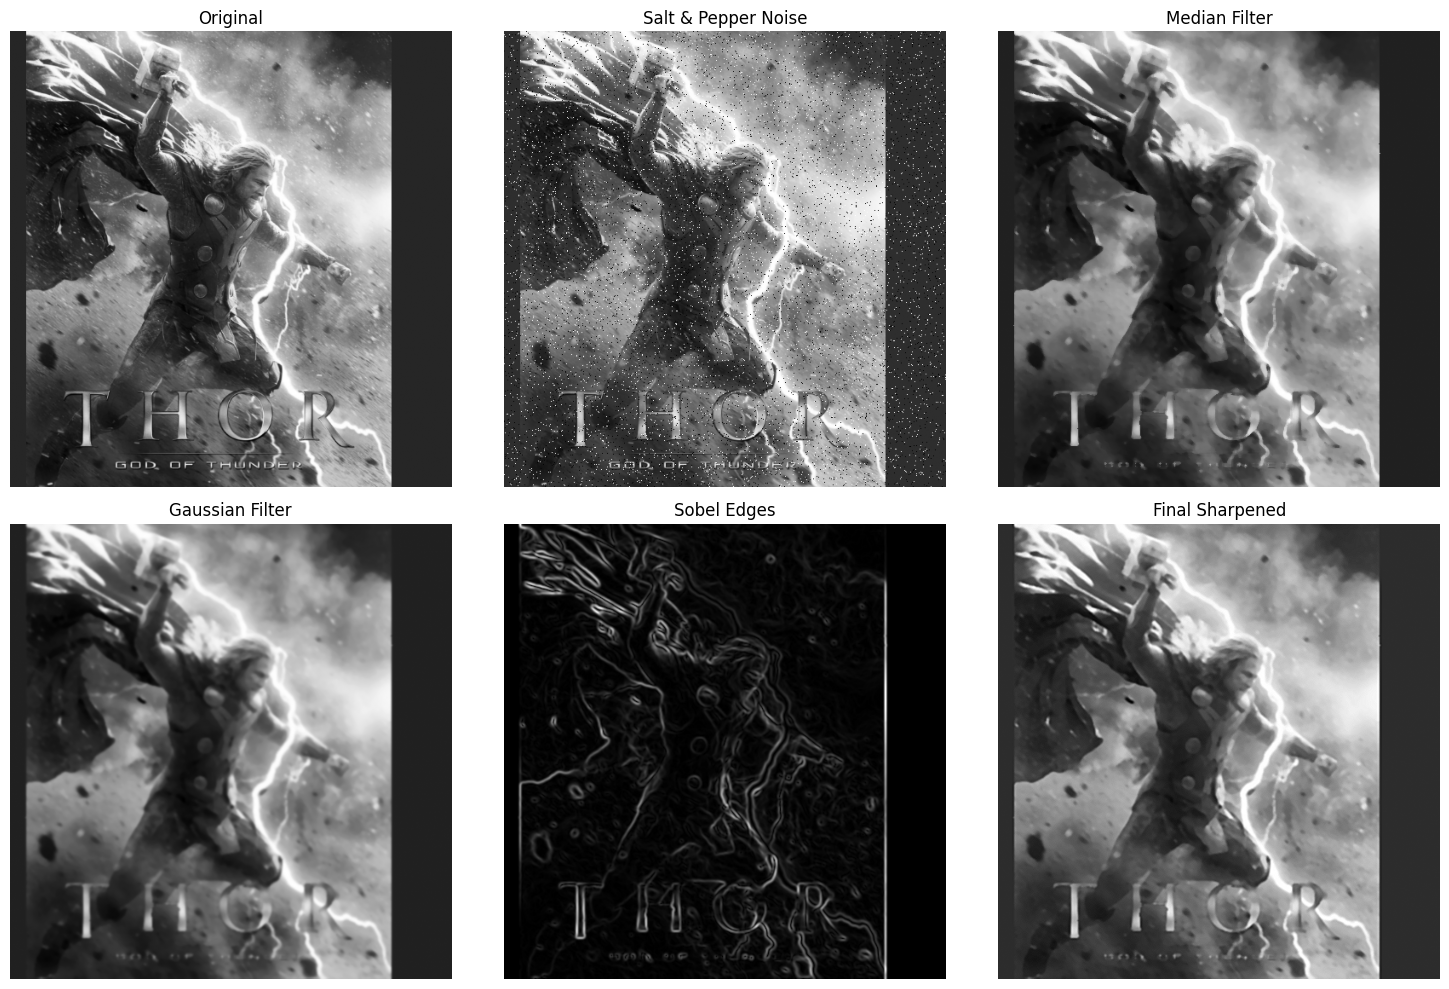

In [18]:

img = cv2.imread("/content/247076.png")


gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

noisy = gray.copy()


num_pixels = int(0.02 * gray.size)

rows = np.random.randint(0, gray.shape[0], num_pixels)
cols = np.random.randint(0, gray.shape[1], num_pixels)

noisy[rows, cols] = 255


rows = np.random.randint(0, gray.shape[0], num_pixels)
cols = np.random.randint(0, gray.shape[1], num_pixels)

noisy[rows, cols] = 0


median = cv2.medianBlur(noisy, 5)


gaussian = cv2.GaussianBlur(median, (5, 5), 1)


sobel_x = cv2.Sobel(gaussian, cv2.CV_64F, 1, 0, ksize=3)
sobel_y = cv2.Sobel(gaussian, cv2.CV_64F, 0, 1, ksize=3)

sobel = cv2.magnitude(
    sobel_x.astype(np.float32),
    sobel_y.astype(np.float32)
)

sobel = cv2.normalize(
    sobel,
    None,
    0,
    255,
    cv2.NORM_MINMAX
).astype(np.uint8)
kernel = np.array([
    [0, -1, 0],
    [-1, 5, -1],
    [0, -1, 0]
])
sharpened = cv2.filter2D(gaussian, -1, kernel)
plt.figure(figsize=(15, 10))
plt.subplot(2, 3, 1)
plt.imshow(gray, cmap="gray")
plt.title("Original")
plt.axis("off")
plt.subplot(2, 3, 2)
plt.imshow(noisy, cmap="gray")
plt.title("Salt & Pepper Noise")
plt.axis("off")
plt.subplot(2, 3, 3)
plt.imshow(median, cmap="gray")
plt.title("Median Filter")
plt.axis("off")
plt.subplot(2, 3, 4)
plt.imshow(gaussian, cmap="gray")
plt.title("Gaussian Filter")
plt.axis("off")
plt.subplot(2, 3, 5)
plt.imshow(sobel, cmap="gray")
plt.title("Sobel Edges")
plt.axis("off")
plt.subplot(2, 3, 6)
plt.imshow(sharpened, cmap="gray")
plt.title("Final Sharpened")
plt.axis("off")
plt.tight_layout()
plt.show()

**Task # 06:**

Load a binary image (or threshold a grayscale image to make it binary). Apply erosion with a 3×3 structuring element and display the original binary image next to the eroded result.

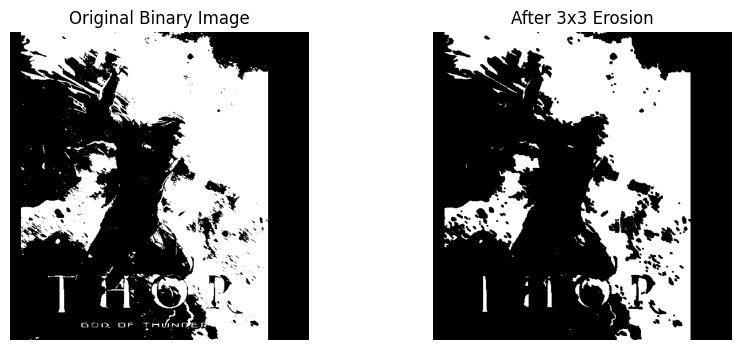

In [19]:

gray = cv2.imread("/content/247076.png", cv2.IMREAD_GRAYSCALE)

_, binary = cv2.threshold(
    gray,
    127,
    255,
    cv2.THRESH_BINARY
)
kernel = np.ones((3, 3), np.uint8)


eroded = cv2.erode(
    binary,
    kernel,
    iterations=1
)
plt.figure(figsize=(10, 4))
plt.subplot(1, 2, 1)
plt.imshow(binary, cmap="gray")
plt.title("Original Binary Image")
plt.axis("off")
plt.subplot(1, 2, 2)
plt.imshow(eroded, cmap="gray")
plt.title("After 3x3 Erosion")
plt.axis("off")
plt.show()